[![Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/code/maryrobynbernabe/kulintang-5-testing-the-best-model)

# Load the best model

## Load the model

In [1]:
#load the model
import pickle

model_name = "/kaggle/input/notebooks/maryrobynbernabe/kulintang-4-classification-model-development/rf_best_model.pkl"
file_name = open(model_name, 'rb')
final_model = pickle.load(file_name)
print("Model is loaded")

Model is loaded


# Load the test dataset

In [2]:
import pandas as pd
#read the data file
df_test = pd.read_csv("/kaggle/input/notebooks/maryrobynbernabe/kulintang-3-train-test-split-csv/test_set.csv")
df_test.head()

,video_segment_name,RMSE,SPECTRAL_CENTROID,SPECTRAL_BANDWIDTH,ROLLOFF,ZERO_CROSSING_RATE,MFCC_FEATURE_0,MFCC_FEATURE_1,MFCC_FEATURE_2,MFCC_FEATURE_3,...,MFCC_FEATURE_11,MFCC_FEATURE_12,MFCC_FEATURE_13,MFCC_FEATURE_14,MFCC_FEATURE_15,MFCC_FEATURE_16,MFCC_FEATURE_17,MFCC_FEATURE_18,MFCC_FEATURE_19,label
0,IMG_0079_part4.mov,0.074279,824.784218,742.036387,1146.643066,0.052321,-360.80756,180.964570,-5.716828,-27.921083,...,21.713823,19.980824,1.300567,2.111620,4.443696,3.829234,-7.244342,-19.688082,-8.291594,4
1,IMG_0092_part5.mov,0.096206,1058.691700,763.509071,1398.415903,0.068585,-349.24020,145.001890,-20.154152,-44.954792,...,3.558468,-1.061922,-4.151087,-18.858686,-17.484415,6.751639,18.643690,12.777710,13.444060,5
2,IMG_0113_part2.mov,0.082792,833.775182,837.783913,1340.185547,0.050107,-365.67830,165.891040,-10.313600,-26.896162,...,-4.357621,23.699467,14.519338,1.636591,7.823964,18.715128,18.430424,2.228519,-4.265099,2
3,IMG_0026_part2.mov,0.116547,829.970077,939.317160,1399.244103,0.040077,-320.75745,165.961930,9.296667,-26.853132,...,10.488697,-7.528155,-6.091860,9.044275,22.409372,24.324890,6.841595,-5.165628,5.904742,2
4,IMG_0212_part1.mov,0.072301,1143.334685,1439.072667,2084.900296,0.050041,-351.37335,126.804726,-18.521122,4.040197,...,18.018242,12.914463,10.952389,6.540925,2.893174,3.431541,-7.017755,-10.989840,-2.744940,1


## Set the label column

In [3]:
LABEL_COLUMN = "label"

## Print the unique labels

In [4]:
LABELS = list(df_test[LABEL_COLUMN].unique())
# sort the labels
# LABELS.sort()
print(LABELS)

[np.int64(4), np.int64(5), np.int64(2), np.int64(1), np.int64(7), np.int64(6), np.int64(3), np.int64(8)]


# Get the predictions on test data

In [5]:
#getting predictions data
columns_to_drop = ['video_segment_name', LABEL_COLUMN]

test_data_list = df_test.drop(columns=columns_to_drop).values
y_true = df_test[LABEL_COLUMN].values
# y_true = [x + 1 for x in y_true]
y_pred = final_model.predict(test_data_list)
print("Predictions: {}".format(y_pred))

Predictions: [4 5 2 2 2 1 5 4 1 1 7 6 3 7 7 8 1 1 1 8 3 5 4 6 4 5 2 3 6 5 1 1 4 1 4 7 4
 2 5 7 8 5 1 7 6 6 6 6 8 4 1 4 3 5 2 2 7 5 7 6 5 5 8 1 6 8 4 4 5 1 1 7 4 3
 5 1 7 7 7 4 2 4 1 8 3 5 2 1 6 4 3 2 3 5 7 3 1 5 2 4 7 1 4 1 6 4 3 3 4 4 3
 8 1 6 5 2 8 2 2 3 8 5 2 3 2 3 8 6 2 2 1 7 1 2 3 3 8 4 2 5 7 7 7 2 1 3 1 4
 4 6 5 4 8 6 3 8 2 2 6 4 6 3 2 6 2 7 2 5 2 7 1 7 3 3 1 4 8 1 1 8 2 5 2 4 6
 4 5 3 7 2 2 4 2 7 6 5 5 6 1 4 3 2 8 8 5 1 1 5 1 4 3 3 1 1 8 2]


## Print labels and predictions info

In [6]:
print("True Labels: {}".format(y_true))
print(len(y_true))
print(len(y_pred))

True Labels: [4 5 2 2 1 1 5 4 1 1 7 6 3 7 7 8 1 1 1 8 3 6 4 6 4 6 2 3 6 6 1 1 4 1 4 6 4
 2 5 7 8 5 1 7 6 6 6 6 8 4 1 4 3 6 2 2 7 6 7 7 5 5 8 1 6 8 4 4 5 1 1 7 4 3
 5 1 7 7 7 4 2 4 1 8 3 5 2 1 6 4 3 2 3 5 7 3 1 5 3 4 7 1 4 1 7 4 3 3 5 5 3
 8 1 6 5 2 8 3 2 3 8 5 2 3 2 3 8 6 2 2 1 7 1 2 3 3 8 4 2 5 7 7 6 2 1 3 1 4
 4 6 5 3 8 6 4 8 2 2 6 5 6 3 2 6 2 7 2 5 2 7 1 6 3 2 1 4 8 1 1 8 2 5 3 4 6
 4 5 4 6 2 2 4 2 7 6 6 4 4 1 4 2 2 8 8 6 1 1 5 1 4 3 3 1 3 8 3]
216
216


## Fuction for Confusion Matrix

## Plot the confusion matrix

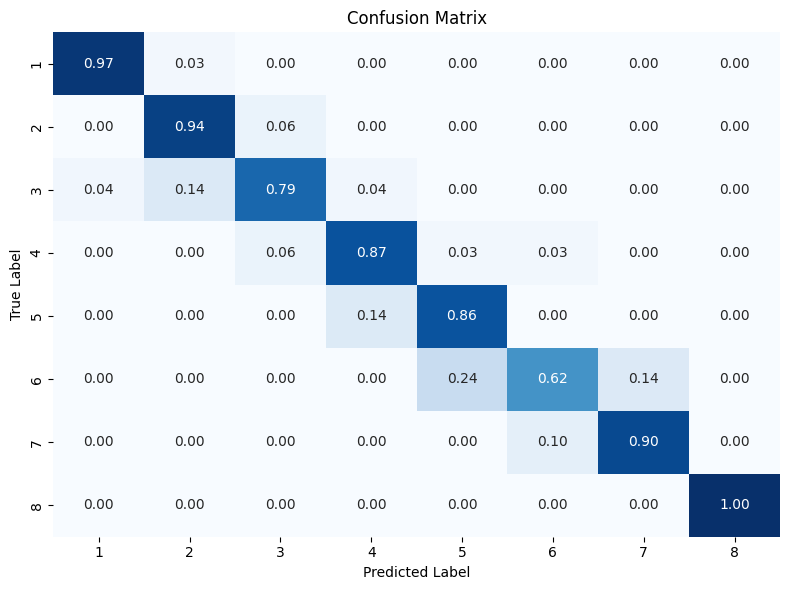

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, classes=None, figsize=(8, 6),
                          title='Confusion Matrix', cmap='Blues',
                          normalize=False, save_path=None):
    """
    Plot a confusion matrix using Seaborn.

    Parameters:
    y_true (array-like): Ground truth labels
    y_pred (array-like): Predicted labels
    classes (list, optional): List of class labels
    figsize (tuple): Figure size
    title (str): Title for the plot
    cmap (str): Color map
    normalize (bool): Whether to normalize the matrix
    save_path (str): Path to save the figure (optional)
    """
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Create figure
    plt.figure(figsize=figsize)

    # Create heatmap
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd',
                cmap=cmap, cbar=False,
                xticklabels=classes, yticklabels=classes)

    # Add labels and title
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(title)

    # Adjust layout
    plt.tight_layout()

    # Save if path is provided
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)

    plt.show()

# Example usage:
class_names = ['1', '2', '3', '4', '5', '6', '7', '8']
plot_confusion_matrix(y_true, y_pred, classes=class_names, normalize=True)

## Create classification report

In [8]:
#classification reports
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           1       0.97      0.97      0.97        35
           2       0.85      0.94      0.89        31
           3       0.85      0.79      0.81        28
           4       0.87      0.87      0.87        31
           5       0.70      0.86      0.78        22
           6       0.86      0.62      0.72        29
           7       0.83      0.90      0.86        21
           8       1.00      1.00      1.00        19

    accuracy                           0.87       216
   macro avg       0.87      0.87      0.86       216
weighted avg       0.87      0.87      0.86       216

